# 07.P · Solution: the December stock forecast

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/project/solution.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

H = 5                                                   # forecast 5 weeks ahead
ORIGINS = pd.date_range("2011-04-03", periods=8, freq="4W-SUN")      # 3 Apr ... 16 Oct 2011

def backtest(forecast_fn, series=None, origins=ORIGINS, h=H):
    """Rolling-origin backtest: at each origin, fit on the past, forecast h weeks, score MAE."""
    series = weekly if series is None else series
    rows = []
    for origin in origins:
        train = series[series.index <= origin]
        test = series[series.index > origin].iloc[:h]
        pred = np.asarray(forecast_fn(train, len(test)))
        rows.append({"origin": origin.date(), "MAE": np.abs(test.values - pred).mean()})
    return pd.DataFrame(rows)

def naive(train, h):          return np.repeat(train.iloc[-1], h)
def mean_fc(train, h):        return np.repeat(train.mean(), h)
def seasonal_naive(train, h): return train.iloc[-52:-52 + h].values
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, h):
    """Additive Holt-Winters, seeded with the first year as the starting seasonal pattern."""
    first = train.iloc[:52]
    model = ExponentialSmoothing(
        train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52,
        initialization_method="known", initial_level=first.mean(), initial_trend=0.0,
        initial_seasonal=(first - first.mean()).values).fit()
    return model.forecast(h).values

import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

def sarima(train, h):
    """SARIMA(1,0,1)(0,1,0,52) with a constant: last year's week, corrected by recent errors."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # statsmodels start-value notices, not errors
        model = SARIMAX(train, order=(1, 0, 1), seasonal_order=(0, 1, 0, 52), trend="c").fit(disp=False)
    return model.forecast(h).values

from sklearn.ensemble import HistGradientBoostingRegressor

def daily_table(d):
    """Turn the daily series into a table. Every lag is >= 35 days, so 5 weeks ahead is honest."""
    t = pd.DataFrame({"y": d})
    t["lag_35"] = d.shift(35)
    t["mean_28_lag_35"] = d.shift(35).rolling(28).mean()
    t["dow"] = d.index.day_of_week
    t["month"] = d.index.month
    t["day_of_year"] = d.index.day_of_year
    t["days_to_xmas"] = (pd.to_datetime(d.index.year.astype(str) + "-12-25") - d.index).days
    return t

TABLE = daily_table(daily)
FEATURES = [c for c in TABLE.columns if c != "y"]

def gbm(train, h):
    """Train on daily rows up to the origin, predict the next h weeks of days, sum to weeks."""
    origin = train.index[-1]
    past = TABLE[TABLE.index <= origin].dropna()
    future = TABLE[TABLE.index > origin].iloc[: 7 * h]
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=10, random_state=0)
    model.fit(past[FEATURES], past["y"])
    pred = pd.Series(model.predict(future[FEATURES]), index=future.index).clip(lower=0)
    pred[future["dow"] == 5] = 0                       # ShopWave never trades on Saturdays
    return pred.resample("W").sum().values[:h]

def recursive_gbm(train, h):
    """One-day-ahead model on lag_1 and lag_7; forecast day by day, feeding predictions back in."""
    origin = train.index[-1]
    d = daily[daily.index <= origin].copy()
    t = pd.DataFrame({"y": d, "lag_1": d.shift(1), "lag_7": d.shift(7),
                      "dow": d.index.day_of_week, "month": d.index.month}).dropna()
    feats = ["lag_1", "lag_7", "dow", "month"]
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=10, random_state=0).fit(t[feats], t["y"])
    for day in pd.date_range(origin + pd.Timedelta(days=1), periods=7 * h, freq="D"):
        row = pd.DataFrame({"lag_1": [d.iloc[-1]], "lag_7": [d.iloc[-7]],
                            "dow": [day.day_of_week], "month": [day.month]})
        d.loc[day] = 0.0 if day.day_of_week == 5 else max(model.predict(row)[0], 0.0)
    return d[d.index > origin].resample("W").sum().values[:h]

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


## Task 1: the split

train: 100 weeks to 2011-10-30; test: 5 weeks 2011-11-06 to 2011-12-04


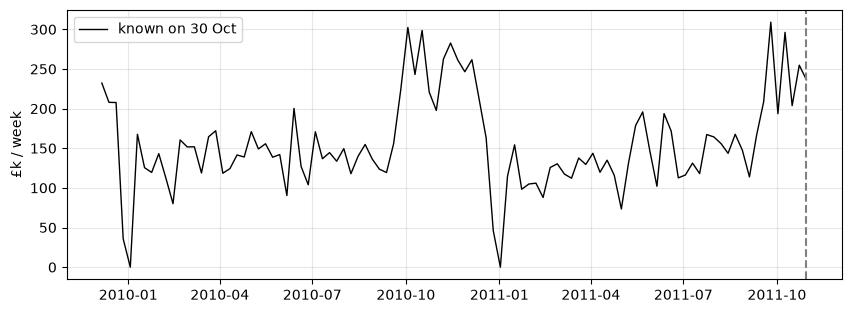

In [2]:
CUTOFF = pd.Timestamp("2011-10-30")                 # "today": the buyers must order this week
train = weekly[weekly.index <= CUTOFF]
test = weekly[weekly.index > CUTOFF]                # 6 Nov - 4 Dec 2011, hidden until the end
print(f"train: {len(train)} weeks to {train.index[-1].date()}; test: {len(test)} weeks "
      f"{test.index[0].date()} to {test.index[-1].date()}")

plt.figure(figsize=(10, 3.5))
plt.plot(train.index, train / 1000, color="black", linewidth=1, label="known on 30 Oct")
plt.axvline(CUTOFF, color="gray", linestyle="--"); plt.ylabel("£k / week")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Task 2: honest selection origins

An origin is safe only if its whole 5-week forecast window ends on or before 30 October. Otherwise the backtest scores models on weeks that overlap the test period, and choosing a model by that score would leak the answer into the decision.

In [3]:
selection_origins = ORIGINS[ORIGINS + pd.Timedelta(weeks=H) <= CUTOFF]
print([o.date().isoformat() for o in selection_origins])
print(f"{len(selection_origins)} origins; the 16 October origin is dropped because its window runs to 20 November")

['2011-04-03', '2011-05-01', '2011-05-29', '2011-06-26', '2011-07-24', '2011-08-21', '2011-09-18']
7 origins; the 16 October origin is dropped because its window runs to 20 November


## Task 3: backtest the candidates

Six candidates: the five from the lessons, plus an **average of seasonal naive and recursive GBM**. Module 05.1 showed that averaging models with different errors often beats either alone, and these two make very different mistakes (one copies last year, the other follows recent weeks).

In [4]:
def average_sn_rec(train, h):
    return (seasonal_naive(train, h) + recursive_gbm(train, h)) / 2

candidates = {"seasonal naive": seasonal_naive, "Holt-Winters": holt_winters, "SARIMA": sarima,
              "GBM direct": gbm, "GBM recursive": recursive_gbm, "average (SN + GBM rec.)": average_sn_rec}

def weekly_errors(fn, origins):
    """Absolute error of every forecast week across the backtest (not averaged)."""
    errs = []
    for o in origins:
        tr = weekly[weekly.index <= o]; te = weekly[weekly.index > o].iloc[:H]
        errs.extend(np.abs(te.values - np.asarray(fn(tr, len(te)))))
    return np.array(errs)

In [5]:
errors = {name: weekly_errors(fn, selection_origins) for name, fn in candidates.items()}
board = pd.DataFrame({"mean MAE £": {n: e.mean() for n, e in errors.items()},
                      "80th pct error £": {n: np.percentile(e, 80) for n, e in errors.items()},
                      "worst week £": {n: e.max() for n, e in errors.items()}})
board.sort_values("mean MAE £").round(0)

,mean MAE £,80th pct error £,worst week £
average (SN + GBM rec.),29783.0,46295.0,93441.0
GBM recursive,32005.0,58090.0,101378.0
seasonal naive,33959.0,54543.0,108738.0
GBM direct,34937.0,53002.0,124373.0
SARIMA,36240.0,55825.0,107510.0
Holt-Winters,36487.0,52394.0,123406.0


## Task 4: choose

In [6]:
chosen = board["mean MAE £"].idxmin()
runner_up = board["mean MAE £"].sort_values().index[1]
gap = board.loc[runner_up, "mean MAE £"] - board.loc[chosen, "mean MAE £"]
print(f"chosen: {chosen}  (ahead of {runner_up} by £{gap:,.0f} a week)")

chosen: average (SN + GBM rec.)  (ahead of GBM recursive by £2,223 a week)


The rule was fixed before looking at the test weeks: **lowest mean MAE in the selection backtest wins.** The average of seasonal naive and recursive GBM wins, about £2.2k a week ahead of recursive GBM alone. That margin is small next to a typical week's error (compare it with the 80th-percentile column, about £46k), so we hold the choice loosely.

## Task 5: forecast with a range

SARIMA's statistical intervals were too narrow in 07.4 (85% coverage for "95%"). A simpler and more honest range uses the chosen model's **own backtest errors**: the forecast ± the 80th percentile of its absolute weekly errors. If the past is a guide, roughly 4 weeks in 5 should land inside.

In [7]:
forecast = np.asarray(candidates[chosen](train, len(test)))
band = np.percentile(errors[chosen], 80)
plan = pd.DataFrame({"forecast": forecast, "low": forecast - band, "high": forecast + band},
                    index=test.index.date)
print(f"range = forecast +/- £{band:,.0f}")
(plan / 1000).round(1)

range = forecast +/- £46,295


,forecast,low,high
2011-11-06,259.4,213.1,305.6
2011-11-13,281.9,235.6,328.2
2011-11-20,250.9,204.6,297.2
2011-11-27,256.8,210.5,303.1
2011-12-04,235.1,188.8,281.4


## Task 6: the reveal

In [8]:
plan["actual"] = test.values
plan["inside range"] = (plan["actual"] >= plan["low"]) & (plan["actual"] <= plan["high"])
print(f"{chosen}: MAE £{np.abs(plan['actual'] - plan['forecast']).mean():,.0f}, "
      f"5-week total forecast £{forecast.sum():,.0f} vs actual £{test.sum():,.0f} "
      f"({100 * (forecast.sum() - test.sum()) / test.sum():+.1f}%), "
      f"{plan['inside range'].sum()} of {len(plan)} weeks inside the range")
(plan.drop(columns="inside range") / 1000).round(1).assign(inside=plan["inside range"])

average (SN + GBM rec.): MAE £13,552, 5-week total forecast £1,284,051 vs actual £1,298,376 (-1.1%), 5 of 5 weeks inside the range


,forecast,low,high,actual,inside
2011-11-06,259.4,213.1,305.6,259.4,True
2011-11-13,281.9,235.6,328.2,263.7,True
2011-11-20,250.9,204.6,297.2,276.2,True
2011-11-27,256.8,210.5,303.1,248.2,True
2011-12-04,235.1,188.8,281.4,250.8,True


In [9]:
reveal = {}
for name, fn in candidates.items():
    p = np.asarray(fn(train, len(test)))
    reveal[name] = {"backtest MAE £": board.loc[name, "mean MAE £"], "Nov MAE £": np.abs(test.values - p).mean(),
                    "5-week total error %": 100 * (p.sum() - test.sum()) / test.sum()}
pd.DataFrame(reveal).T.sort_values("Nov MAE £").round(1)

,backtest MAE £,Nov MAE £,5-week total error %
seasonal naive,33958.5,9881.8,1.3
SARIMA,36240.1,9995.0,1.1
Holt-Winters,36486.8,11443.1,-1.0
average (SN + GBM rec.),29782.5,13551.9,-1.1
GBM direct,34937.2,18752.2,-0.9
GBM recursive,32005.2,23546.8,-3.5


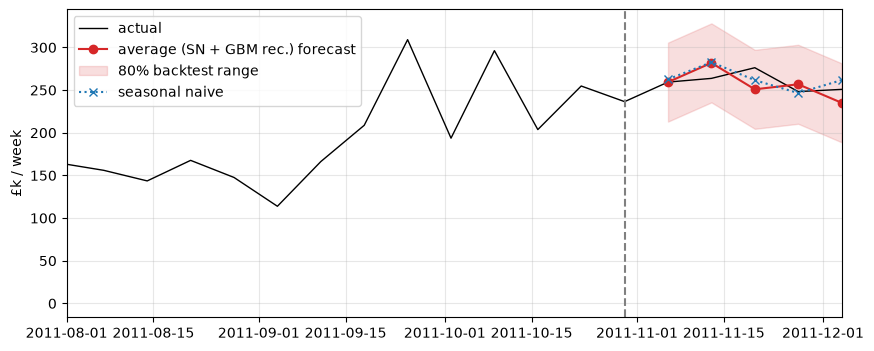

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly / 1000, color="black", linewidth=1, label="actual")
plt.plot(test.index, forecast / 1000, color="tab:red", marker="o", label=f"{chosen} forecast")
plt.fill_between(test.index, (forecast - band) / 1000, (forecast + band) / 1000, color="tab:red", alpha=.15,
                 label="80% backtest range")
plt.plot(test.index, seasonal_naive(train, len(test)) / 1000, color="tab:blue", marker="x",
         linestyle=":", label="seasonal naive")
plt.xlim(pd.Timestamp("2011-08-01"), weekly.index[-1]); plt.axvline(CUTOFF, color="gray", linestyle="--")
plt.ylabel("£k / week"); plt.legend(); plt.grid(alpha=.3); plt.show()

## Task 7: the recommendation

*(Every number below is from the executed cells above.)*

**To the buying team.** Plan for steady peak trading of about **£235k–£282k a week** from 6 November to 4 December, **£1.28m in total** for the five weeks. That is close to the same weeks last year: 2011 has run at about the 2010 level all autumn. Use the weekly forecast for core lines. For best-sellers that sold out last December, stock towards the **high** end of the range (about £46k a week above the forecast), because a stock-out in peak weeks costs far more than some surplus in January.

**How we chose and how it went.** The forecast is the average of "same week last year" and a recursive gradient-boosting model. It was chosen by a fixed rule (lowest backtest MAE, £29.8k a week) on seven origins that never touched these weeks. On the real five weeks:

- The **5-week total** was within **1.1%** of actual (£1.284m forecast vs £1.298m).
- **All 5 weeks** fell inside the range.
- **Week by week**, its MAE of £13.6k ranked only fourth of six. Plain seasonal naive did best (£9.9k), and the backtest's runner-up, recursive GBM, did worst (£23.5k).

That is the main lesson of this project. The backtest ranked the models within a few thousand pounds of each other, which is smaller than a typical week's error, so the ranking on any five particular weeks can flip. Over the totals that matter for ordering, every candidate was within 3.5% of actual. With two years of history, *no* method is reliably better than "same week last year", so the sensible plan is last year's pattern, cross-checked by a model, with honest ranges around it.

**Next steps.**

- Forecast at product level for the 200 lines that make up most of December's revenue (stretch task).
- Add a bank-holiday flag.
- Re-run this backtest monthly as more history arrives. With a third year, Holt-Winters and SARIMA will have a full season to learn from.